# YouTube → dev.to blog agent
**LangGraph + LangChain `create_agent` + OpenRouter + human-in-the-loop**

Turns a YouTube video into a blog post and publishes it to dev.to.

```
ingest ─(rejected)→ END
   ↓
clean_transcript → plan_outline → [write_section × N  (parallel, create_agent + code-check tool)]
   ↓
assemble_post → fact_check (create_agent + transcript-search tool) ─(low score)→ revise_draft ┐
   ↓                    ↑___________________________________________________________________┘
prepare_metadata → human_review  ⏸ interrupt #1 (approve / edit / revise / abort)
   ↓
publish (create_agent + HumanInTheLoopMiddleware)  ⏸ interrupt #2 (approve / edit / reject the tool call)
   ↓
social_and_store → END
```

**How to use**
1. Run the install cell, then paste your two keys in the config cell.
2. Set `VIDEO_ID`, run everything down to *Step 1*. The graph pauses at **human_review**.
3. Read the draft, set `REVIEW_DECISION`, run *Step 2*.
4. The graph pauses again at the **publish tool call**. Set `PUBLISH_DECISION`, run *Step 3*.
   By default the article is saved as a **private draft** on dev.to; edit the call to `published=True` to go live.

In [1]:
%pip install -q -U langchain langchain-openai langgraph youtube-transcript-api yt-dlp requests pydantic

Note: you may need to restart the kernel to use updated packages.


d:\youtube-to-blog\.venv\Scripts\python.exe: No module named pip


## 1. Config & API keys

In [2]:
import os

# 🔑 Set OPENROUTER_API_KEY and DEVTO_API_KEY as environment variables (never hardcode keys).
OPENROUTER_API_KEY = os.environ.get("OPENROUTER_API_KEY", "")
DEVTO_API_KEY = os.environ.get("DEVTO_API_KEY", "")

# Any tool-calling model available on OpenRouter works. Change the slug to whatever you prefer.
MODEL_NAME = "deepseek/deepseek-v4.1-flash"

# Job settings
VIDEO_ID = "ghPb2T0ygSE"            # the part after ?v= in the YouTube URL
ATTRIBUTION_MODE = "credited"       # "own_video" (it's your video) or "credited" (someone else's, adds credit block)
STYLE_EXAMPLES: list[str] = []      # optional: paste 1-3 of your past posts so the output matches your voice
MAX_REVISIONS = 2                   # automatic fact-check -> revise loops before handing to the human anyway
MIN_FAITHFULNESS = 0.85             # share of checked claims that must be supported by the transcript
MAX_NO_CHAPTER_DURATION = 3600      # no chapters + longer than this (seconds) => "cannot be converted to blog"
WINDOW_SECONDS = 300                # when a video has no chapters, split it into windows of this length

for _name, _val in [("OPENROUTER_API_KEY", OPENROUTER_API_KEY), ("DEVTO_API_KEY", DEVTO_API_KEY)]:
    if not _val:
        print(f"⚠️  {_name} is not set yet")

## 2. Imports, state and structured-output schemas

In [3]:
import ast
import json
import operator
import re
from pathlib import Path
from typing import Annotated, Literal, Optional, TypedDict

import requests
import yt_dlp
from pydantic import BaseModel, Field
from youtube_transcript_api import NoTranscriptFound, YouTubeTranscriptApi

from langchain.agents import create_agent
from langchain.agents.middleware import HumanInTheLoopMiddleware
from langchain_core.messages import AIMessage, ToolMessage
from langchain_core.tools import tool
from langchain_openrouter import ChatOpenRouter
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.graph import END, START, StateGraph
from langgraph.types import Command, Send, interrupt


# ---------- Sub-structures ----------
class Chapter(TypedDict):
    title: str
    start: float          # seconds
    end: float
    text: str


class OutlineSection(TypedDict):
    id: str
    heading: str
    chapter_idxs: list[int]   # which chapters feed this section (adjacent chapters can be merged)
    start: float
    end: float
    key_points: list[str]


class SectionDraft(TypedDict):
    section_id: str
    idx: int                  # position in the outline (parallel branches finish in any order)
    markdown: str
    timestamp_link: str


class Claim(TypedDict):
    text: str
    supported: bool
    evidence: str


class SectionTask(TypedDict):
    """Payload sent to each parallel write_section branch (not the full graph state)."""
    idx: int
    section: OutlineSection
    section_text: str
    video_id: str
    video_title: str
    angle: str
    target_reader: str
    glossary: list[str]
    style_examples: list[str]


# ---------- Main graph state ----------
class BlogState(TypedDict, total=False):
    # input / config
    video_id: str
    video_url: str
    attribution_mode: Literal["own_video", "credited"]
    style_examples: list[str]
    max_revisions: int
    min_faithfulness: float

    # ingest
    title: str
    description: str
    channel_name: str
    duration: int
    has_chapters: bool
    chapters: list[Chapter]
    transcript_language: str
    rejection_reason: Optional[str]

    # cleaning / planning
    glossary: list[str]
    cleaned_chapters: list[Chapter]
    angle: str
    target_reader: str
    outline: list[OutlineSection]
    tags: list[str]

    # writing (parallel branches -> reducer merges)
    section_drafts: Annotated[list[SectionDraft], operator.add]
    draft_markdown: str

    # quality loop
    claims: list[Claim]
    faithfulness_score: float
    quality_scores: dict[str, float]
    revision_notes: list[str]
    revision_count: int

    # dev.to metadata
    title_options: list[str]
    final_title: str
    devto_description: str
    devto_tags: list[str]
    canonical_url: Optional[str]
    final_markdown: str

    # human review
    review_status: Literal["pending", "approved", "edited", "revise", "rejected"]
    reviewer_feedback: Optional[str]

    # publish / post-publish
    devto_article_id: Optional[int]
    devto_url: Optional[str]
    publish_status: str
    social_snippets: dict[str, str]

    # control
    errors: Annotated[list[str], operator.add]
    status: str


# ---------- Schemas for structured LLM output ----------
class Glossary(BaseModel):
    terms: list[str] = Field(description="Technical terms, product names and acronyms spelled correctly")


class OutlineSectionModel(BaseModel):
    heading: str
    chapter_idxs: list[int] = Field(description="Indices of the chapters that belong in this section, in order")
    key_points: list[str]


class Outline(BaseModel):
    angle: str = Field(description="One sentence: the blog post's angle")
    target_reader: str
    tags: list[str] = Field(description="Up to 4 lowercase dev.to tags, letters and digits only")
    sections: list[OutlineSectionModel]


class Framing(BaseModel):
    intro: str = Field(description="Hook plus 1-2 paragraphs, markdown, no heading")
    tldr: list[str] = Field(description="3-5 short TL;DR bullets")
    conclusion: str = Field(description="Short conclusion in markdown, no heading")


class ClaimCheck(BaseModel):
    text: str
    supported: bool
    evidence: str = ""


class FactCheck(BaseModel):
    claims: list[ClaimCheck]
    readability: float = Field(description="1-10")
    structure: float = Field(description="1-10")
    revision_notes: list[str]


class Metadata(BaseModel):
    title_options: list[str] = Field(description="3 title options, each under 80 characters")
    description: str = Field(description="One-sentence summary, under 150 characters")
    tags: list[str] = Field(description="Max 4 lowercase tags, letters and digits only")


class Social(BaseModel):
    linkedin: str
    x: str = Field(description="Under 270 characters")

## 3. Helpers

In [4]:
REGISTRY_PATH = Path("published_videos.json")   # remembers which videos were already converted


def fmt_time(seconds: float) -> str:
    seconds = int(seconds)
    h, rem = divmod(seconds, 3600)
    m, s = divmod(rem, 60)
    return f"{h:02d}:{m:02d}:{s:02d}"


def yt_link(video_id: str, seconds: float) -> str:
    return f"https://youtu.be/{video_id}?t={int(seconds)}"


def text_of(content) -> str:
    """Message content can be a string or a list of content blocks, depending on the model."""
    if isinstance(content, str):
        return content
    if isinstance(content, list):
        return "".join(
            part if isinstance(part, str) else part.get("text", "")
            for part in content
            if isinstance(part, (str, dict))
        )
    return str(content)


def last_ai_text(result: dict) -> str:
    for msg in reversed(result["messages"]):
        if isinstance(msg, AIMessage) and text_of(msg.content).strip():
            return text_of(msg.content).strip()
    return ""


def clean_tags(tags: list[str], limit: int = 4) -> list[str]:
    out: list[str] = []
    for t in tags:
        t = re.sub(r"[^a-z0-9]", "", t.lower())
        if t and t not in out:
            out.append(t)
    return out[:limit]


def split_words(text: str, size: int) -> list[str]:
    words = text.split()
    return [" ".join(words[i:i + size]) for i in range(0, len(words), size)] or [""]


def load_registry() -> dict:
    return json.loads(REGISTRY_PATH.read_text()) if REGISTRY_PATH.exists() else {}


def save_to_registry(video_id: str, url: str, title: str) -> None:
    reg = load_registry()
    reg[video_id] = {"url": url, "title": title}
    REGISTRY_PATH.write_text(json.dumps(reg, indent=2))

## 4. Tools
Static tools are used by the ingest node and the agents. Run-specific tools (transcript search, publish) are built by small factories so they close over the current job's data.

In [5]:
@tool
def get_video_metadata(video_id: str) -> dict:
    """Fetch YouTube metadata: title, description, channel, duration in seconds, and chapters
    (list of {title, start, end}). `chapters` is an empty list when the video has none."""
    url = f"https://www.youtube.com/watch?v={video_id}"
    with yt_dlp.YoutubeDL({"quiet": True, "skip_download": True}) as ydl:
        info = ydl.extract_info(url, download=False)
    chapters = [
        {"title": c["title"], "start": float(c["start_time"]), "end": float(c["end_time"])}
        for c in (info.get("chapters") or [])
    ]
    return {
        "title": info.get("title", ""),
        "description": info.get("description", "") or "",
        "channel": info.get("channel") or info.get("uploader") or "",
        "duration": int(info.get("duration") or 0),
        "chapters": chapters,
    }


@tool
def get_transcript(video_id: str, languages: Optional[list[str]] = None) -> dict:
    """Fetch the video transcript. Returns {language, snippets: [{text, start, duration}]}.
    Tries the given languages (default English) and falls back to any available transcript."""
    api = YouTubeTranscriptApi()
    try:
        fetched = api.fetch(video_id, languages=languages or ["en", "en-US", "en-GB"])
    except NoTranscriptFound:
        fetched = next(iter(api.list(video_id))).fetch()
    snippets = [{"text": s.text, "start": s.start, "duration": s.duration} for s in fetched]
    return {"language": getattr(fetched, "language_code", "unknown"), "snippets": snippets}


@tool
def check_already_published(video_id: str) -> dict:
    """Check the local registry to see whether this video was already converted and published."""
    entry = load_registry().get(video_id)
    return {"already_published": entry is not None, "url": (entry or {}).get("url")}


@tool
def validate_code_syntax(language: str, code: str) -> str:
    """Check that a code block is syntactically valid. Supports python and json.
    Returns 'OK' or a description of the error. Other languages are not checked."""
    lang = language.strip().lower()
    try:
        if lang in ("python", "py"):
            ast.parse(code)
        elif lang == "json":
            json.loads(code)
        else:
            return f"Not checked: no validator for '{language}'."
    except (SyntaxError, ValueError) as e:
        return f"INVALID {language}: {e}"
    return "OK"


def make_search_transcript_tool(chapters: list[Chapter]):
    """Build a keyword-overlap search tool over the cleaned transcript (no embeddings needed)."""
    passages: list[tuple[str, float, str]] = []
    for ch in chapters:
        for piece in split_words(ch["text"], 60):
            if piece:
                passages.append((ch["title"], ch["start"], piece))

    @tool
    def search_transcript(query: str) -> str:
        """Search the video transcript for passages relevant to a claim. Returns the top 3 passages
        with their chapter and timestamp. Use it to verify each factual claim in the draft."""
        q = {w for w in re.findall(r"[a-z0-9]+", query.lower()) if len(w) > 3}
        scored = []
        for title, start, piece in passages:
            overlap = len(q & set(re.findall(r"[a-z0-9]+", piece.lower())))
            if overlap:
                scored.append((overlap, title, start, piece))
        scored.sort(key=lambda x: -x[0])
        if not scored:
            return "No relevant passage found."
        return "\n\n".join(f"[{fmt_time(s)} | {t}] {p}" for _, t, s, p in scored[:3])

    return search_transcript


def make_publish_tool(payload: dict):
    """The article body is bound here, so the model never has to re-type the post.
    The model only chooses `published`; a human gets to approve/edit/reject the call."""

    @tool
    def publish_to_devto(published: bool = False) -> str:
        """Send the prepared article to dev.to. published=False saves a private draft on dev.to;
        published=True makes it public."""
        article = {
            "title": payload["title"],
            "body_markdown": payload["body_markdown"],
            "published": bool(published),
            "tags": payload["tags"],
            "description": payload["description"],
        }
        if payload.get("canonical_url"):
            article["canonical_url"] = payload["canonical_url"]
        try:
            r = requests.post(
                "https://dev.to/api/articles",
                headers={
                    "api-key": DEVTO_API_KEY,
                    "Content-Type": "application/json",
                    "Accept": "application/vnd.forem.api-v1+json",
                },
                json={"article": article},
                timeout=30,
            )
        except requests.RequestException as e:
            return f"ERROR: request to dev.to failed: {e}"
        if r.status_code not in (200, 201):
            return f"ERROR {r.status_code}: {r.text[:300]}"
        data = r.json()
        return json.dumps({"id": data.get("id"), "url": data.get("url"), "published": data.get("published")})

    return publish_to_devto

## 5. LLM (OpenRouter) and agents

In [6]:
def make_llm(model: str = MODEL_NAME, temperature: float = 0.2) -> ChatOpenRouter:
    return ChatOpenRouter(
        model=model,
        api_key=OPENROUTER_API_KEY,
        base_url="https://openrouter.ai/api/v1",
        temperature=temperature,
        default_headers={"X-Title": "yt-to-devto-agent"},
    )


llm = make_llm()


def structured(schema):
    """function_calling works on far more OpenRouter models than native json_schema mode."""
    return llm.with_structured_output(schema, method="function_calling")


SECTION_WRITER_PROMPT = """You are a technical writer turning ONE section of a YouTube video transcript into one section of a dev.to blog post.

Rules:
- Use ONLY information present in the transcript excerpt. Never invent facts, numbers, commands or APIs.
- Start with the section heading as a level-2 markdown heading (## ...).
- Clear, direct prose in short paragraphs. Use bullets only where they genuinely help.
- If the excerpt contains code, commands or config, put them in fenced code blocks with a language tag. Before returning a python or json block, call the validate_code_syntax tool and fix any error.
- Do not write an introduction or conclusion for the whole post. Do not say "the transcript" or "the speaker".
- Return ONLY the markdown for this section."""

FACT_CHECK_PROMPT = """You are a meticulous fact-checker. You receive a blog post draft that was written from a video transcript.
1. List the 8-12 most important factual claims in the draft (numbers, names, commands, cause-and-effect statements).
2. For EACH claim call search_transcript, then decide whether the transcript supports it.
3. Finish with a plain-text report: one line per claim as `SUPPORTED|UNSUPPORTED | claim | evidence`, then 2-4 sentences on readability and structure, and a list of concrete fixes."""

# One writer agent is reused for every section (it is stateless between calls).
section_writer = create_agent(
    model=llm,
    tools=[validate_code_syntax],
    system_prompt=SECTION_WRITER_PROMPT,
    name="section_writer",
)


def build_fact_checker(chapters: list[Chapter]):
    return create_agent(
        model=llm,
        tools=[make_search_transcript_tool(chapters)],
        system_prompt=FACT_CHECK_PROMPT,
        name="fact_checker",
    )


def build_publisher(payload: dict):
    """HITL #2: the publish tool call is paused until a human approves, edits or rejects it."""
    review_text = (
        f"About to send this article to dev.to:\n"
        f"  title: {payload['title']}\n"
        f"  tags: {', '.join(payload['tags'])}\n"
        f"  body: {len(payload['body_markdown'])} characters\n"
        f"published=False saves a private draft on dev.to. Edit the call to published=True to go live."
    )
    return create_agent(
        model=llm,
        tools=[make_publish_tool(payload)],
        system_prompt=(
            "You publish a finished article to dev.to. Call publish_to_devto exactly once with "
            "published=false, then reply with one short sentence reporting the result."
        ),
        middleware=[
            HumanInTheLoopMiddleware(
                interrupt_on={
                    "publish_to_devto": {
                        "allowed_decisions": ["approve", "edit", "reject"],
                        "description": review_text,
                    }
                }
            )
        ],
        name="publisher",
    )

## 6. Graph nodes

In [7]:
def ingest_video(state: BlogState) -> dict:
    vid = state["video_id"]
    meta = get_video_metadata.invoke({"video_id": vid})
    base = {
        "video_url": f"https://www.youtube.com/watch?v={vid}",
        "title": meta["title"],
        "description": meta["description"],
        "channel_name": meta["channel"],
        "duration": meta["duration"],
        "has_chapters": bool(meta["chapters"]),
        "status": "ingested",
    }

    # Gate 1: no chapters and too long -> stop before downloading the transcript
    if not meta["chapters"] and meta["duration"] > MAX_NO_CHAPTER_DURATION:
        return {**base, "rejection_reason": (
            f"Cannot be converted to blog: the video has no chapters and is "
            f"{fmt_time(meta['duration'])} long (limit {fmt_time(MAX_NO_CHAPTER_DURATION)})."
        )}

    # Gate 2: already converted
    reg = check_already_published.invoke({"video_id": vid})
    if reg["already_published"]:
        return {**base, "rejection_reason": f"Already converted and published: {reg['url']}"}

    # Gate 3: transcript must exist
    try:
        tr = get_transcript.invoke({"video_id": vid})
    except Exception as e:
        return {**base, "rejection_reason": f"No transcript available ({type(e).__name__}).", "errors": [str(e)]}
    snippets = tr["snippets"]
    if not snippets:
        return {**base, "rejection_reason": "Transcript is empty."}

    # Chapters: real ones, or fixed windows when the video has none
    if meta["chapters"]:
        spans = [(c["title"], c["start"], c["end"]) for c in meta["chapters"]]
    else:
        total = max(meta["duration"], int(snippets[-1]["start"]) + 1)
        spans = [
            (f"Part {i + 1} ({fmt_time(s)})", float(s), float(min(s + WINDOW_SECONDS, total)))
            for i, s in enumerate(range(0, total, WINDOW_SECONDS))
        ]
    spans[-1] = (spans[-1][0], spans[-1][1], max(spans[-1][2], snippets[-1]["start"] + 1))

    chapters: list[Chapter] = []
    for title, start, end in spans:
        lines = [s["text"].replace("\n", " ") for s in snippets if start <= s["start"] < end]
        chapters.append({"title": title, "start": start, "end": end, "text": " ".join(lines)})

    return {**base, "chapters": chapters, "transcript_language": tr["language"], "rejection_reason": None}


def route_after_ingest(state: BlogState):
    if state.get("rejection_reason"):
        print("⛔", state["rejection_reason"])
        return END
    return "clean_transcript"


def clean_transcript(state: BlogState) -> dict:
    glossary = structured(Glossary).invoke(
        "List the technical terms, product names, libraries and acronyms that appear in this video's "
        f"title and description, spelled correctly.\n\nTitle: {state['title']}\n\nDescription:\n{state['description'][:3000]}"
    ).terms

    prompts, owners = [], []
    for ci, ch in enumerate(state["chapters"]):
        for piece in split_words(ch["text"], 2500):        # keep each LLM call a manageable size
            prompts.append(
                "Clean this auto-generated video transcript. Remove filler words and false starts, fix obvious "
                "speech-recognition errors and punctuation. Do NOT summarise, add, or remove information. "
                f"Spell these terms correctly when they appear: {', '.join(glossary) or 'n/a'}.\n\n"
                f"Return only the cleaned text.\n\nTRANSCRIPT:\n{piece}"
            )
            owners.append(ci)
    outputs = llm.batch(prompts, config={"max_concurrency": 4})

    texts = [[] for _ in state["chapters"]]
    for ci, out in zip(owners, outputs):
        texts[ci].append(text_of(out.content).strip())
    cleaned = [{**ch, "text": " ".join(texts[i])} for i, ch in enumerate(state["chapters"])]
    return {"glossary": glossary, "cleaned_chapters": cleaned, "status": "cleaned"}


def plan_outline(state: BlogState) -> dict:
    chapters = state["cleaned_chapters"]
    overview = "\n".join(
        f"[{i}] {c['title']} ({fmt_time(c['start'])}-{fmt_time(c['end'])}): {' '.join(c['text'].split()[:60])}..."
        for i, c in enumerate(chapters)
    )
    plan = structured(Outline).invoke(
        "You are planning a dev.to blog post based on a video. Choose an angle and the target reader, then "
        "design the section list. Each section lists the chapter indices it draws from; adjacent chapters may "
        "be merged, and every chapter should be used at least once. Aim for 3-8 sections.\n\n"
        f"Video title: {state['title']}\n\nChapters:\n{overview}"
    )

    valid = [s for s in plan.sections if s.chapter_idxs and all(0 <= i < len(chapters) for i in s.chapter_idxs)]
    if not valid:  # fallback: one section per chapter
        valid = [OutlineSectionModel(heading=c["title"], chapter_idxs=[i], key_points=[]) for i, c in enumerate(chapters)]

    outline: list[OutlineSection] = []
    for n, s in enumerate(valid):
        idxs = sorted(set(s.chapter_idxs))
        outline.append({
            "id": f"sec_{n:02d}",
            "heading": s.heading,
            "chapter_idxs": idxs,
            "start": chapters[idxs[0]]["start"],
            "end": chapters[idxs[-1]]["end"],
            "key_points": s.key_points,
        })
    return {
        "angle": plan.angle,
        "target_reader": plan.target_reader,
        "tags": clean_tags(plan.tags),
        "outline": outline,
        "status": "planned",
    }


def fan_out_sections(state: BlogState):
    """Send one small task per section so they are written in parallel."""
    chapters = state["cleaned_chapters"]
    return [
        Send("write_section", {
            "idx": n,
            "section": sec,
            "section_text": "\n\n".join(chapters[i]["text"] for i in sec["chapter_idxs"]),
            "video_id": state["video_id"],
            "video_title": state["title"],
            "angle": state["angle"],
            "target_reader": state["target_reader"],
            "glossary": state["glossary"],
            "style_examples": state.get("style_examples", []),
        })
        for n, sec in enumerate(state["outline"])
    ]


def write_section(task: SectionTask) -> dict:
    sec = task["section"]
    style = ""
    if task["style_examples"]:
        style = "\n\nMatch the voice of these example posts by the author:\n" + "\n---\n".join(task["style_examples"])
    prompt = (
        f"Post angle: {task['angle']}\nTarget reader: {task['target_reader']}\n"
        f"Section heading: {sec['heading']}\nKey points: {'; '.join(sec['key_points']) or 'n/a'}\n"
        f"Correct spellings: {', '.join(task['glossary']) or 'n/a'}{style}\n\n"
        f"TRANSCRIPT EXCERPT:\n{task['section_text']}"
    )
    result = section_writer.invoke({"messages": [{"role": "user", "content": prompt}]})
    link = yt_link(task["video_id"], sec["start"])
    markdown = f"{last_ai_text(result)}\n\n[▶ Watch this part of the video ({fmt_time(sec['start'])})]({link})"
    return {"section_drafts": [{"section_id": sec["id"], "idx": task["idx"], "markdown": markdown, "timestamp_link": link}]}


def assemble_post(state: BlogState) -> dict:
    """Sections are kept verbatim; the LLM only writes the intro, TL;DR and conclusion around them."""
    drafts = sorted(state["section_drafts"], key=lambda d: d["idx"])
    body = "\n\n".join(d["markdown"] for d in drafts)
    framing = structured(Framing).invoke(
        f"Write the framing for a dev.to blog post titled '{state['title']}'.\n"
        f"Angle: {state['angle']}\nReader: {state['target_reader']}\n\n"
        "Write an engaging intro, 3-5 TL;DR bullets and a short conclusion. Use only what the sections below say.\n\n"
        f"SECTIONS:\n{body}"
    )
    tldr = "\n".join(f"- {b}" for b in framing.tldr)
    draft = f"{framing.intro.strip()}\n\n**TL;DR**\n\n{tldr}\n\n{body}\n\n## Conclusion\n\n{framing.conclusion.strip()}"
    return {"draft_markdown": draft, "status": "assembled"}


def fact_check(state: BlogState) -> dict:
    checker = build_fact_checker(state["cleaned_chapters"])
    result = checker.invoke({"messages": [{"role": "user", "content": f"DRAFT:\n\n{state['draft_markdown']}"}]})
    verdict = structured(FactCheck).invoke(
        "Convert this fact-check report into the structured format. Keep claims short.\n\n" + last_ai_text(result)
    )
    claims = [c.model_dump() for c in verdict.claims]
    score = (sum(c["supported"] for c in claims) / len(claims)) if claims else 1.0   # computed, not self-reported
    notes = list(verdict.revision_notes) + [f"Unsupported claim: {c['text']}" for c in claims if not c["supported"]]
    return {
        "claims": claims,
        "faithfulness_score": round(score, 2),
        "quality_scores": {"readability": verdict.readability, "structure": verdict.structure},
        "revision_notes": notes,
        "status": "fact_checked",
    }


def route_after_fact_check(state: BlogState):
    ok = state["faithfulness_score"] >= state.get("min_faithfulness", MIN_FAITHFULNESS)
    if ok or state.get("revision_count", 0) >= state.get("max_revisions", MAX_REVISIONS):
        return "prepare_metadata"      # good enough, or out of automatic retries -> let the human decide
    return "revise_draft"


def revise_draft(state: BlogState) -> dict:
    feedback = state.get("reviewer_feedback")
    notes = "\n".join(f"- {n}" for n in state.get("revision_notes", []))
    prompt = (
        "Revise this blog post draft. Remove or correct every unsupported claim and apply the notes. "
        "Keep the structure, headings, code blocks and the '▶ Watch this part' links. "
        "Do not add facts that are not in the original draft.\n\n"
        f"NOTES:\n{notes or 'n/a'}\n"
        + (f"\nREVIEWER FEEDBACK (highest priority):\n{feedback}\n" if feedback else "")
        + f"\nDRAFT:\n{state['draft_markdown']}\n\nReturn only the full revised markdown."
    )
    revised = text_of(llm.invoke(prompt).content).strip()
    return {
        "draft_markdown": revised,
        "revision_count": state.get("revision_count", 0) + 1,
        "reviewer_feedback": None,
        "review_status": "pending",
        "status": "revised",
    }


def prepare_metadata(state: BlogState) -> dict:
    meta = structured(Metadata).invoke(
        "Create dev.to metadata for this post: 3 title options, a one-sentence description, and at most 4 tags "
        f"(letters and digits only).\n\nAngle: {state['angle']}\nSuggested tags: {', '.join(state.get('tags', []))}\n\n"
        f"POST:\n{state['draft_markdown'][:6000]}"
    )
    title = meta.title_options[0] if meta.title_options else state["title"]
    url = state["video_url"]
    if state.get("attribution_mode") == "own_video":
        credit = f"> This post is the written version of my video. [Watch it on YouTube]({url})."
    else:
        credit = (
            f"> This post is an AI-assisted written adaptation of a video by **{state.get('channel_name') or 'the creator'}**. "
            f"All ideas belong to the original creator. [Watch the original on YouTube]({url})."
        )
    final_md = "{% embed " + url + " %}\n\n" + credit + "\n\n" + state["draft_markdown"]
    return {
        "title_options": meta.title_options,
        "final_title": title,
        "devto_description": meta.description[:150],
        "devto_tags": clean_tags(meta.tags or state.get("tags", [])),
        "final_markdown": final_md,
        "review_status": "pending",
        "status": "ready_for_review",
    }


def human_review(state: BlogState) -> dict:
    """HITL #1: pause the graph and show the draft. Resume with a dict, see 'Step 2'."""
    unsupported = [c["text"] for c in state.get("claims", []) if not c["supported"]]
    decision = interrupt({
        "kind": "draft_review",
        "title": state["final_title"],
        "title_options": state.get("title_options", []),
        "description": state["devto_description"],
        "tags": state["devto_tags"],
        "faithfulness_score": state.get("faithfulness_score"),
        "quality_scores": state.get("quality_scores"),
        "unsupported_claims": unsupported,
        "markdown": state["final_markdown"],
        "how_to_resume": 'approve | edit (+markdown/title/tags) | revise (+feedback) | abort',
    })
    action = decision.get("action", "approve")
    if action == "approve":
        return {"review_status": "approved"}
    if action == "edit":
        update = {"review_status": "edited", "final_markdown": decision.get("markdown", state["final_markdown"])}
        if decision.get("title"):
            update["final_title"] = decision["title"]
        if decision.get("tags"):
            update["devto_tags"] = clean_tags(decision["tags"])
        return update
    if action == "revise":
        return {"review_status": "revise", "reviewer_feedback": decision.get("feedback", "")}
    return {"review_status": "rejected"}


def route_after_review(state: BlogState):
    return {"approved": "publish", "edited": "publish", "revise": "revise_draft"}.get(state["review_status"], END)


def publish(state: BlogState) -> dict:
    payload = {
        "title": state["final_title"],
        "body_markdown": state["final_markdown"],
        "tags": state["devto_tags"],
        "description": state["devto_description"],
        "canonical_url": state.get("canonical_url"),
    }
    publisher = build_publisher(payload)           # pauses on the publish_to_devto tool call (HITL #2)
    result = publisher.invoke({"messages": [{"role": "user", "content": "Publish the article now."}]})

    tool_msgs = [m for m in result["messages"] if isinstance(m, ToolMessage) and m.name == "publish_to_devto"]
    if not tool_msgs:
        return {"publish_status": "not_published", "status": "publish_skipped"}
    content = text_of(tool_msgs[-1].content)
    try:
        # If the reviewer edited the call, the middleware prepends a notice to the tool result,
        # so locate the JSON object instead of parsing the whole string.
        start = content.index('{"id"')
        data, _ = json.JSONDecoder().raw_decode(content[start:])
        return {
            "devto_article_id": data["id"],
            "devto_url": data["url"],
            "publish_status": "published" if data.get("published") else "saved_as_draft",
            "status": "published",
        }
    except (ValueError, KeyError, TypeError):
        return {"publish_status": f"not_published: {content[:200]}", "errors": [content[:300]], "status": "publish_failed"}


def social_and_store(state: BlogState) -> dict:
    if not state.get("devto_url"):
        return {"status": "finished_without_publish"}
    snippets = structured(Social).invoke(
        "Write a LinkedIn post (3-5 short lines, no hashtags spam) and an X post for this new article. "
        f"Include the link {state['devto_url']}.\n\nTitle: {state['final_title']}\nSummary: {state['devto_description']}"
    )
    save_to_registry(state["video_id"], state["devto_url"], state["final_title"])
    return {"social_snippets": {"linkedin": snippets.linkedin, "x": snippets.x}, "status": "done"}

## 7. Build the graph
The checkpointer is what makes `interrupt()` and the HITL middleware work: it saves the state at each pause so you can resume later with the same `thread_id`.

In [8]:
builder = StateGraph(BlogState)

builder.add_node("ingest_video", ingest_video)
builder.add_node("clean_transcript", clean_transcript)
builder.add_node("plan_outline", plan_outline)
builder.add_node("write_section", write_section)
builder.add_node("assemble_post", assemble_post)
builder.add_node("fact_check", fact_check)
builder.add_node("revise_draft", revise_draft)
builder.add_node("prepare_metadata", prepare_metadata)
builder.add_node("human_review", human_review)
builder.add_node("publish", publish)
builder.add_node("social_and_store", social_and_store)

builder.add_edge(START, "ingest_video")
builder.add_conditional_edges("ingest_video", route_after_ingest, ["clean_transcript", END])
builder.add_edge("clean_transcript", "plan_outline")
builder.add_conditional_edges("plan_outline", fan_out_sections, ["write_section"])
builder.add_edge("write_section", "assemble_post")
builder.add_edge("assemble_post", "fact_check")
builder.add_conditional_edges("fact_check", route_after_fact_check, ["revise_draft", "prepare_metadata"])
builder.add_edge("revise_draft", "fact_check")
builder.add_edge("prepare_metadata", "human_review")
builder.add_conditional_edges("human_review", route_after_review, ["publish", "revise_draft", END])
builder.add_edge("publish", "social_and_store")
builder.add_edge("social_and_store", END)

graph = builder.compile(checkpointer=InMemorySaver())

print(graph.get_graph().draw_mermaid())   # paste into https://mermaid.live to see the diagram

---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	ingest_video(ingest_video)
	clean_transcript(clean_transcript)
	plan_outline(plan_outline)
	write_section(write_section)
	assemble_post(assemble_post)
	fact_check(fact_check)
	revise_draft(revise_draft)
	prepare_metadata(prepare_metadata)
	human_review(human_review)
	publish(publish)
	social_and_store(social_and_store)
	__end__([<p>__end__</p>]):::last
	__start__ --> ingest_video;
	assemble_post --> fact_check;
	clean_transcript --> plan_outline;
	fact_check -.-> prepare_metadata;
	fact_check -.-> revise_draft;
	human_review -.-> __end__;
	human_review -.-> publish;
	human_review -.-> revise_draft;
	ingest_video -.-> __end__;
	ingest_video -.-> clean_transcript;
	plan_outline -.-> write_section;
	prepare_metadata --> human_review;
	publish --> social_and_store;
	revise_draft --> fact_check;
	write_section --> assemble_post;
	social_and_store --> __end__;
	classDef default fill:#f2f0ff,line-

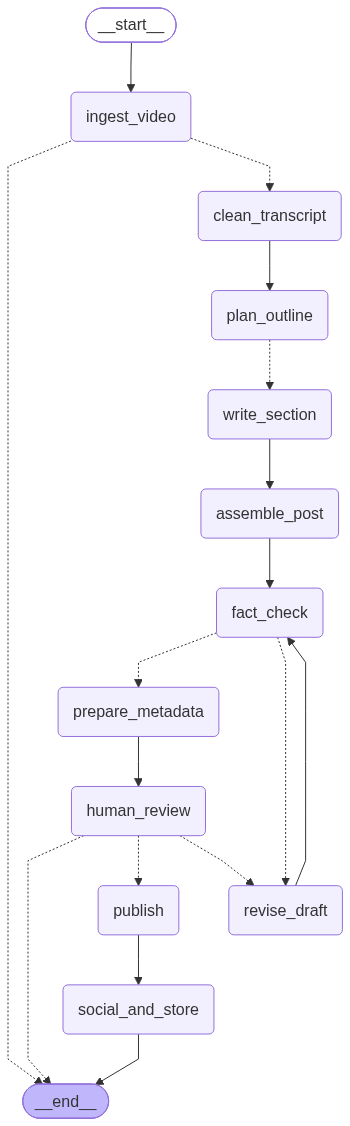

In [9]:
from IPython.display import Image, display

# Generate the PNG bytes and display the image
img_bytes = graph.get_graph().draw_mermaid_png()
display(Image(img_bytes))

## 8. Run helpers

In [10]:
config = {"configurable": {"thread_id": f"yt-{VIDEO_ID}"}, "recursion_limit": 60}


def run(payload) -> None:
    """Stream the graph, print each finished node, then show whatever it is waiting for."""
    for chunk in graph.stream(payload, config, stream_mode="updates"):
        for node, update in chunk.items():
            if node != "__interrupt__" and isinstance(update, dict):
                print(f"✓ {node}")
    show_pending()


def show_pending() -> None:
    snap = graph.get_state(config)
    if not snap.interrupts:
        print(f"\n— graph finished (status: {snap.values.get('status')}) —")
        return
    for it in snap.interrupts:
        v = it.value
        if isinstance(v, dict) and v.get("kind") == "draft_review":
            print("\n⏸  HUMAN REVIEW — draft is ready")
            print("Title:", v["title"], "| options:", v["title_options"])
            print("Tags:", v["tags"], "| faithfulness:", v["faithfulness_score"], "| quality:", v["quality_scores"])
            if v["unsupported_claims"]:
                print("Unsupported claims:", *v["unsupported_claims"], sep="\n  - ")
            print("\n" + v["markdown"][:2500] + ("\n…[truncated]" if len(v["markdown"]) > 2500 else ""))
        elif isinstance(v, dict) and "action_requests" in v:
            print("\n⏸  PUBLISH TOOL CALL — needs your decision")
            for a in v["action_requests"]:
                print(a["name"], a["args"], "\n" + a.get("description", ""))
        else:
            print("⏸ ", v)

## Step 1 — Run until the draft is ready for review

In [11]:
initial_state = {
    "video_id": VIDEO_ID,
    "attribution_mode": ATTRIBUTION_MODE,
    "style_examples": STYLE_EXAMPLES,
    "max_revisions": MAX_REVISIONS,
    "min_faithfulness": MIN_FAITHFULNESS,
    "revision_count": 0,
    "errors": [],
}
run(initial_state)

✓ ingest_video
✓ clean_transcript
✓ plan_outline
✓ write_section
✓ write_section
✓ write_section
✓ write_section
✓ write_section
✓ write_section
✓ write_section
✓ assemble_post
✓ fact_check
✓ prepare_metadata

⏸  HUMAN REVIEW — draft is ready
Title: The 2026 Agentic AI Roadmap: From LLM Basics to Production | options: ['The 2026 Agentic AI Roadmap: From LLM Basics to Production', '7 Steps From LLM Fundamentals to Production-Ready AI Agents', 'A Durable 2026 Roadmap for Learning Agentic AI the Right Way']
Tags: ['ai', 'agents', 'llm', 'machinelearning'] | faithfulness: 1.0 | quality: {'readability': 8.0, 'structure': 6.0}

{% embed https://www.youtube.com/watch?v=ghPb2T0ygSE %}

> This post is an AI-assisted written adaptation of a video by **Krish Naik**. All ideas belong to the original creator. [Watch the original on YouTube](https://www.youtube.com/watch?v=ghPb2T0ygSE).

Getting started with agentic AI looks deceptively easy. You pick an LLM, reach for a framework, and build an agen

## Step 2 — Review the draft (HITL #1)
Choose one decision, then run the cell:
- `{"action": "approve"}` — publish as-is
- `{"action": "edit", "markdown": "...", "title": "...", "tags": ["python", "..."]}` — you edited the post
- `{"action": "revise", "feedback": "Make the intro shorter and add a code example"}` — send it back to the writer
- `{"action": "abort"}` — stop here

In [15]:
REVIEW_DECISION = {"action": "approve"}

run(Command(resume=REVIEW_DECISION))


— graph finished (status: done) —


## Step 3 — Approve the publish tool call (HITL #2)
- `{"type": "approve"}` — run the call as proposed (**saves a private draft** on dev.to)
- `{"type": "edit", "edited_action": {"name": "publish_to_devto", "args": {"published": True}}}` — go live
- `{"type": "reject", "message": "Not yet"}` — don't publish

In [16]:
# PUBLISH_DECISION = {"type": "approve"}
PUBLISH_DECISION = {"type": "edit", "edited_action": {"name": "publish_to_devto", "args": {"published": True}}}

run(Command(resume={"decisions": [PUBLISH_DECISION]}))


— graph finished (status: done) —


## Result

In [17]:
final = graph.get_state(config).values
print("Status:        ", final.get("status"))
print("Publish status:", final.get("publish_status"))
print("dev.to URL:    ", final.get("devto_url"))
print("Errors:        ", final.get("errors"))
if final.get("social_snippets"):
    print("\nLinkedIn:\n" + final["social_snippets"]["linkedin"])
    print("\nX:\n" + final["social_snippets"]["x"])

Status:         done
Publish status: saved_as_draft
dev.to URL:     https://dev.to/swayam_dc1eefb8839da110de/the-2026-agentic-ai-roadmap-from-llm-basics-to-production-5d7d-temp-slug-6504857
Errors:         []

LinkedIn:
The 2026 agentic AI race won't be won by prompt tricks — it'll be won by engineering discipline.

My new article lays out a 7-step roadmap from LLM fundamentals to production: ReAct orchestration, retrieval, safety guardrails, and the observability that keeps it all honest.

It's the sequence I wish more teams followed before shipping agents into the wild.

Full read: https://dev.to/swayam_dc1eefb8839da110de/the-2026-agentic-ai-roadmap-from-llm-basics-to-production-5d7d-temp-slug-6504857

X:
The 2026 Agentic AI Roadmap: LLM basics → ReAct → RAG → safety → production. A 7-step path for devs who want agents that actually ship. https://dev.to/swayam_dc1eefb8839da110de/the-2026-agentic-ai-roadmap-from-llm-basics-to-production-5d7d-temp-slug-6504857
